# Task01 for the chapter **Statistical Learning**

This task is separated into 3 parts.

The first part is about the dataset **college**

And we will discuss it in this notebook.

-----

It contains a number of variables for **777 different universities and colleges in the US**. The
variables are:

- Private: Public/private indicator
- Apps: Number of applications received
- Accept: Number of applicants accepted
- Enroll: Number of new students enrolled
- Top10perc: New students from top 10 % of high school class
- Top25perc: New students from top 25 % of high school class
- F.Undergrad: Number of full-time undergraduates
- P.Undergrad: Number of part-time undergraduates
- Outstate: Out-of-state tuition
- Room.Board: Room and board costs
- Books: Estimated book costs
- Personal: Estimated personal spending
- PhD: Percent of faculty with Ph.D.s
- Terminal: Percent of faculty with terminal degree
- S.F.Ratio: Student/faculty ratio
- perc.alumni: Percent of alumni who donate
- Expend: Instructional expenditure per student
- Grad.Rate: Graduation rate

In [3]:
# (a) We shall read the dataset

import pandas as pd
college = pd.read_csv('/content/College.csv')

In [6]:
# (b) first we will look at the data by using "college.head()"

print("Let's get a look at the data")
print(college.head())

# We see here there's something unusual with the data "Look at the name of the first column"
college.rename({"Unnamed: 0": "College"}, axis='columns', inplace=True)
print('------------------------------')
print(college.head())

Let's get a look at the data
                     Unnamed: 0 Private  Apps  Accept  Enroll  Top10perc  \
0  Abilene Christian University     Yes  1660    1232     721         23   
1            Adelphi University     Yes  2186    1924     512         16   
2                Adrian College     Yes  1428    1097     336         22   
3           Agnes Scott College     Yes   417     349     137         60   
4     Alaska Pacific University     Yes   193     146      55         16   

   Top25perc  F.Undergrad  P.Undergrad  Outstate  Room.Board  Books  Personal  \
0         52         2885          537      7440        3300    450      2200   
1         29         2683         1227     12280        6450    750      1500   
2         50         1036           99     11250        3750    400      1165   
3         89          510           63     12960        5450    450       875   
4         44          249          869      7560        4120    800      1500   

   PhD  Terminal  S.F.Ratio

In [9]:
# (c) we want to produce a numerical summary "for numerical columns" of the variables in the data set
print(college.describe())

               Apps        Accept       Enroll   Top10perc   Top25perc  \
count    777.000000    777.000000   777.000000  777.000000  777.000000   
mean    3001.638353   2018.804376   779.972973   27.558559   55.796654   
std     3870.201484   2451.113971   929.176190   17.640364   19.804778   
min       81.000000     72.000000    35.000000    1.000000    9.000000   
25%      776.000000    604.000000   242.000000   15.000000   41.000000   
50%     1558.000000   1110.000000   434.000000   23.000000   54.000000   
75%     3624.000000   2424.000000   902.000000   35.000000   69.000000   
max    48094.000000  26330.000000  6392.000000   96.000000  100.000000   

        F.Undergrad   P.Undergrad      Outstate   Room.Board        Books  \
count    777.000000    777.000000    777.000000   777.000000   777.000000   
mean    3699.907336    855.298584  10440.669241  4357.526384   549.380952   
std     4850.420531   1522.431887   4023.016484  1096.696416   165.105360   
min      139.000000      

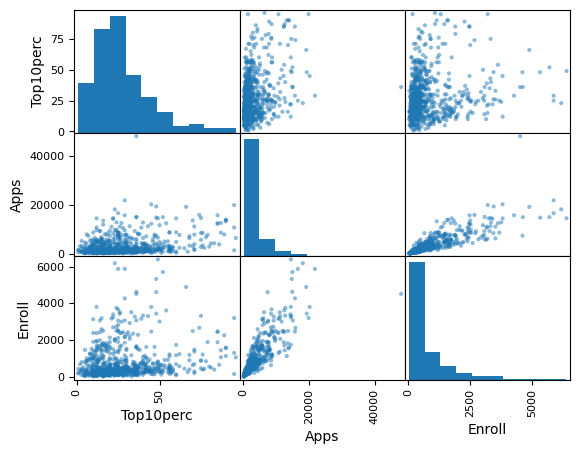

In [18]:
# (d) let's produce a scatterplot matrix of the first columns [Top10perc, Apps, Enroll]

C = {'Top10perc': college['Top10perc'], 'Apps': college['Apps'], 'Enroll':college['Enroll']}
C = pd.DataFrame(data=C)
pd.plotting.scatter_matrix(C, alpha=0.5, diagonal='hist');

Axes(0.1,0.15;0.8x0.75)


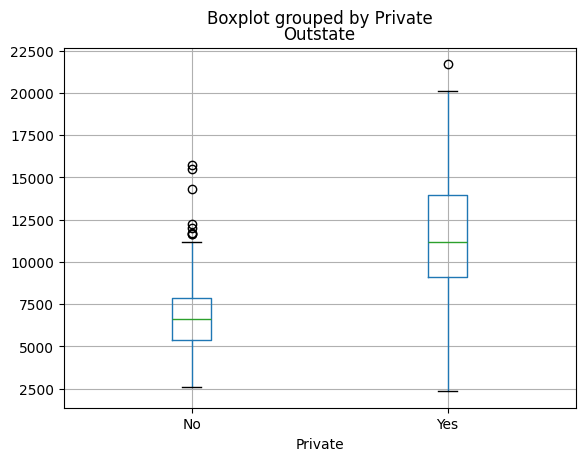

In [34]:
# (e) let's draw a boxplot to produce side-by-side boxplots of 'Outstate' and 'Private'

print(college.boxplot(column='Outstate', by='Private'))

The count is:
 Elite
No     699
Yes     78
Name: count, dtype: int64
Axes(0.1,0.15;0.8x0.75)


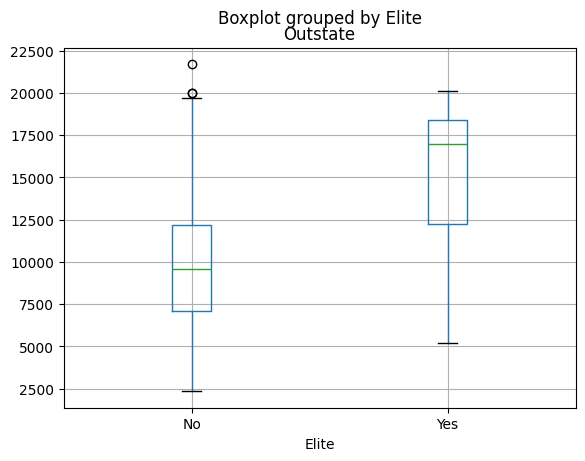

In [35]:
"""
  (f)
  Create a new qualitative variable, called Elite,
  by binning the Top10perc variable into two groups based on
  whether or not the proportion of students coming from the top 10% of their high school classes exceeds 50%.
  And Use the value_counts() method of college['Elite'] to see how
  many elite universities there are. Finally, use the boxplot() method
  again to produce side-by-side boxplots of Outstate versus Elite.
"""

college['Elite'] = pd.cut(college['Top10perc'], bins=[0, 50, 100], labels =['No', 'Yes'])
print("The count is:\n", college['Elite'].value_counts())
print(college.boxplot(column='Outstate', by='Elite'))

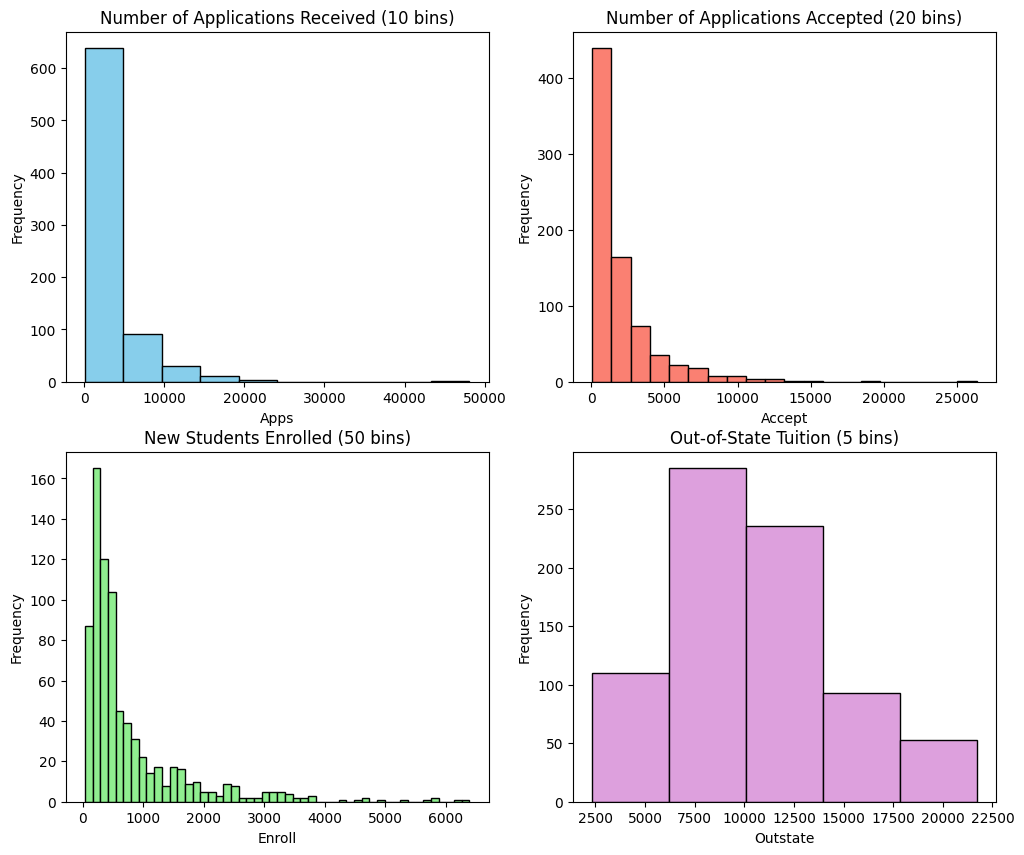

In [37]:
"""
  (g)
  Use the plot.hist() method of college to produce some his-
  tograms with differing numbers of bins for a few of the quanti-
  tative variables. The command plt.subplots(2, 2) may be use-
  ful: it will divide the plot window into four regions so that four
  plots can be made simultaneously.
"""

import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

college['Apps'].plot.hist(ax=axes[0, 0], bins=10, color='skyblue', edgecolor='black')
axes[0, 0].set_title('Number of Applications Received (10 bins)')
axes[0, 0].set_xlabel('Apps')

college['Accept'].plot.hist(ax=axes[0, 1], bins=20, color='salmon', edgecolor='black')
axes[0, 1].set_title('Number of Applications Accepted (20 bins)')
axes[0, 1].set_xlabel('Accept')

college['Enroll'].plot.hist(ax=axes[1, 0], bins=50, color='lightgreen', edgecolor='black')
axes[1, 0].set_title('New Students Enrolled (50 bins)')
axes[1, 0].set_xlabel('Enroll')

college['Outstate'].plot.hist(ax=axes[1, 1], bins=5, color='plum', edgecolor='black')
axes[1, 1].set_title('Out-of-State Tuition (5 bins)')
axes[1, 1].set_xlabel('Outstate')

plt.show()